<a href="https://colab.research.google.com/github/thelastjedi001/autolens/blob/main/MATH1130_RQ3_Google_Colab_Notebook_Dhruv_v2_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MATH 1130 Final Project — Supporting Research Question 3 (RQ3)
## Pitch Location & Swing-and-Miss (`Whiff%`) Analysis: Toronto Blue Jays (2025 Postseason)
**Author:** Dhruv  
**Dataset:** `TOR_Pitches_Feature_Engineered.csv` ($N = 2,788$ pitches, $1,300$ swings)  
**Assigned Columns:** `pitch_type`, `zone`, `stand`, `is_swing`, `is_whiff`  
**Key Formula:** $\text{Whiff\%} = \left(\frac{\sum \text{is\_whiff}}{\sum \text{is\_swing}}\right) \times 100$

### Step 1: Load Libraries & Dataset (Zero-Config Auto-Loader)
Just click **Play** (`Shift + Enter`)! This cell automatically loads `TOR_Pitches_Feature_Engineered.csv` if it is in your Colab folder, OR automatically reconstructs the exact 2,788-row dataset in memory so it runs immediately without hanging on file uploads.

In [ ]:
import os, io, zlib, base64
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest

csv_filename = 'TOR_Pitches_Feature_Engineered.csv'
if os.path.exists(csv_filename):
    df = pd.read_csv(csv_filename)
    rq3 = df[['pitch_type', 'zone', 'stand', 'is_swing', 'is_whiff']].copy()
    print('Loaded TOR_Pitches_Feature_Engineered.csv from local Colab directory!')
else:
    _EMBEDDED_DATA = 'eNqVXcmO7MYRvPtb+tC1cDsTaLzBzKk57ywYtmS9iyxAAgT7693TQ7IiMiPJ8a1AFMliLblERiZ///HnP3796c///P7z5b///u3nyx9//v23f15+/PHTH3/9+O1fH42/fv3xyy9/u90u/eV+uV6uH82U1/byfkmpXa+PZrqkj+a0XV0uqVzePi8vjx4fzWfn3Jrd877H496eb0mf943ttucj1scN7b7Hu/f2tDW3Hil8xse37J330a0vv+6Pvrfn3an3tY3v6r4FmoN+eW3N5wdsbegytvF1PE1b521I0JfeDR1SbWOmNrwwiflde68L2gcPgS4V3lnMe2g91q85m5HJrdK+y66fuyVtOw53jr8xGreY+Q5upaHc4c62DLVdH7bNv1wSbRi5p/aRh2M5uS7undocwU7ObV7w6GSxEZ6zKB+NJy3rHQnvQZnQcXPtUYQwgTlcXvbT9Tq38WH7xu19Y80gnV7aAmH70Wdol6dN+Lx8Tkrae79tXQZupnUo2/NeP16vjma3fs7rvD9i/tae/GhvK/noUY1c23rDzBc837p3sc9+Dq9vs7PN60N0d6050Iff2+X7PqulzR6I/3Gbvff25Bd8ydSe3OMZtrtZn9ZVsiTQN1XurX3L0UKDlDHyrkjhjVs+GpZSIyi3Tr5o30f7vDUhBu35e5txFHR0YOCzH/1R/G6n+3F5bE2hph7PzpsCfN811sdIYLONQj4/btzO3OPJXRsGbpSU+Min7UYyGa5+h+3txwOndqMQ1LvMsle322gmX9qQPq6nNjf7dtuuiz4DdAeZCS9NVjnti+AsnG1c27Ezh9g+cBM4q7TA6xPpenV52xqrpPIaONLXQzOOUNe5relkOR8xVKWDtDrozIB+66E3CI3OmFbr0ei0aSCH+HG90HDvNOnbaUv6kGc9YZHSjF4LI+u94lhX4OiVcNg/H20nhudu67M+p8cD5ZcXd9Q28CSWPZn5cm+6tcGj7QHC13xTlXb2qB4CBv9NW2ePoYANbx7tbcZRS3swyisc0NK+vYcpTGY6vUNStd6Rr7yFFsYqqL6howB7rRenoImSzaTydruxJeyg1sdkPtbGI/l4Z9Y6rFp5mJ5vgRkp7ctcu30Et9eHD7rLePIUfCt/RScmKxT232hCsxDrbHOMrcfITk7ykmxCQd4+JwlR+zrz9XYsQbcaz/vqPyzry9gmBb2bLwNZ5Lvi3B2MuZmz824cbOb72qPpk7nt+nn/gKcNS1apeEZ1Nk1aTZPmSORmr6JTkcUn3Miaxsu6zdsRHt41039kG9nsV/R0PgwFbFc0wawts5t/aTd93trC+8umC17PrVnZzE9uD6DPhUoY3bJm9wjs56Oz3F3dCZCx22IJzVOjFTLYXHiYwaTp1OUX8DHedjPq6Vx5vX0j07e2o7qpKiWE1jtzIKeS7t4JhWcMxCSsDG9PsoNqpeB7UyXvbAvWyPO6k0Fn3arWNF4d+J+paKCxN3Yb+JrCoB3Qg94XaBRrhdv08xz5tjHhYYd3+vyDmGOfxJ+0pxfHxxj9jYQi1HswSoqh1Hu0ccqDLjyhSvyiVK5SKtvXoPxty/kGPn0TdXAdH5NNdwsvvJO8BOE+GDFqH7gqIiFXJMzGuGAPlmdS0OHikBrRpWqDaWpba2gbdNLOuNX1yT1DekQg7dAkjT8e4PLBwobs1CL2uGnnRBhrw4HQWQDRvT7ZnemZzhrciH5O1T5nAQSvaPThDJR4nds8kAXJO6+jDenQMzgyzbBMnxidM2qM8TC0Zj2wtkW7j2w4Ez6xtinKcAA8CmOgqRmyHl3rcUHuzqleMVDlfSR2OQxiKr7Qi3syP5JA0AyIOAZdssAWCSwcSFB53NKg0rWZIxO5jxLrqH5irXAMxC2avmhVZ4PW7Xj6jk9OAFXihFahhM11Df7D4vc+jrVKJBu9WPC2bCJyyQvvSer/rEEetFXS0XTLaKTxi812HL33hkfVoGPBnp5skJWBgAiDWlykU4hxwCZ1hEqg2xY/oThlGMPyZiUjYBXe7qPDdhwBvtiJNTM6R2KX8vLSzETzLXqrIYw52mhsYmGyeAzNtX3EWQYn3VYHyWx1gZrNmzQfWNJ3aOjSll4lc6ckya3JjFenQT34isjHC+zSF1a4NiC4zm0RJxpE9oFXhNHL7MUT6j8DGVUREFxhE0LcEyv5g9kvci8rWPDpPnu4eYtkiodn4To8jXsODKfm9aemDncfwsZ30oYL2GegmuKQao+QBzvkFDLZ4jGkl9eB9BZVsvu0aqyuGPdNxmve1ClRztmnMN9jR2iCJR/Eai7jFXvDJ1BElz28wqE8h9NAKCpExlLT5oO7nJqnlw49PXbjhEc5issA+ZkAI26YquMHlZxrKTaLn1d9tWG0TyCm164tCTEVQcKdSaAj8xuKMjCNBQCPH0SMw/p3KlxgXKhJif8XveG/CB0lqcZsGL5Z7ZYJFaLwRrxOHi5jT+M0Gk7mHYcr+yD8RzS2t//H4EjC8kGTbdGhtQWN0U7IfMWcSiYQRQhAYHskz9eRAH4CReisvk6YOzcwlm+ngQLWrPUg9uy9zKTDpLjehcW+4HZkb06rOGYYmET3QBqmwjRDcz55AgRjzUO7WgUjkr2XwvCRD5AKcD6Kj95m2hmBdzx6MY62EKIvDEt00TFzsSxuEiYtLtMGnGmBO2vDEUXw8bzsNQvi6iwoIiKOjPWbuGQS2FA7rKQs1MlZVdTIREwPvshAa3D81um8Iv3Hxh9dMCvp0OA69zaq4JcBMZzJhC6FiQ3boJqlTxSlSKSqJSeUvFyU77MBZ4VQmPGs4uVekV1nDMgPnoq3a4uEodXPaZDYLIWVEx9XRB/XbTLotUx6/2aySaU9if5CxXDtm4pOn8VLcNp8cFcEGlqzE/c1QMpfrx55flwO8N5e2MfNKk2GL9exmD4ypsxqVqbiHjAKTUAS25M8XpOINy2hcQiE1kkENtBXYxduMqFigbNWtwrOTgOPr56COEVZOzDuOYwNRaGnEXF0799oU8bAw11zfHuwrj3E5njiUSxahze1BBsEb/E2S7AN1bKB8Y3qPt6+3nZwtFIA/g3dpTQRVbVVh9tjklBxyh6WIifiOwWue0HturG6KQHzxvMTb7H7ldDi8hHiYMYNFCOozgKsvpqQs2BMWUMMJwXEuZlOZdSeifZ9uIKm9Z2mPGD+8cx5KpzZTfUrd97tUsBhMjM3oRm1N6tn2Tml+UYh/DY/JyvBxH9JzoSEABhhuD2BWNTpabBTIpx3lNdVKFBDzuhl7CbCMu0ev3qMUQRnDnzCUdFF42yeKOOnC5w7SmY6yRtamMqiovaTdN26L3zDeRLQJDOpRsGgDOM33GfQOXGVYYxtsEEUowZpZ0FEaJRE4BGOVTlBQ8wCFm+xCSRB+EY9EixOg+idADKWQPtTAHcIOCIl4AJ/oS15VkvMBE86XkrTGOSaKRZ/cCR4iZQxGdlW0aybZK5iQwLuMrY7DsfYENSrIHeY0IjleRSbE5bYAPzKJ9FeE8QCQ7yWJ9f0mbTK9D60G+6oXzp4k9LYToNn9Jmo10neikV0K/tDPrTZeXfa7uas8x2GQPCbzS/0gSZvZ80OBR1QTghYxKBsiEVLG3BdygECdeAzfaGLAZGJKpW914t7XCyth/m6wJ4r8Ua15pLF/+pJNt4NGdVB1t9IAGAAXt2ldSeNAZzP3udSSXrP9QDjV9r4FmJemK2uQaXCfH0Xj1pQjY/ko/lwXGDEEBqsg6iRjqB5GBRkupzGDA5g+EASY5KOu27INBEVnaMGyQWIHVEmWwjlGtGEOBAQyJpUBXH9UxreBVmlBgaIkRKw14/IJxQIy0e2dnLJ8IU3vgp/lvNEMekXLtI3spTaO/McroTrvF8wuRhEfi+CxWBsfHg9FCp2WeRmSFl4VCBDQNe+xrTXUeeLI55fReqQoVmOfi1FevnVRRNIaCf9mZI5uG12ttPdIZAxtxtmz2YDfJEeZmn+HPop7g62oz2ZKc7sUjkVaxtstF6sBGphdu2LcOFPUrSUx59EJB3COSoB1hfqGEXULAjfcQYMkrd6i8BB4s4hZz0K0KjCNEhhbTQlLOvwTmMtAqgwO3XUebCDOMpcPibgzHYuWfTA5YuYCAfFTorIlV0CBo4PSLjyBW9BDHbxMKnQGJ3LmUiOvJ4Oopkp3OqHWfKNdvWtaRCbN/vWTvq+YScPE7fznyC0nxA2hMQwoHYDE8xyVzIzrq8H2ZCrYkl2o7+E7nIQ5RnFVjecs7F5iyoZa3uPl1DFjFCAiT5djGpH2WRHbb1H5IYkqmpEEHRkrXK0D3clpoBlL4ohkYsCVG+XLKxCAMxZnJ9Kdgg4f0ezuRPRH4zk31ru9hdztKCkC0rZIUglyJJ9WDhxy/EL3jFnBq4OokPzLFeyqKOYzI6lZsJRJipKoaSioxaycNFM1kX26dVk7zJT0HoP1mrmSgewxAFMOaqM2zBBpvMBM9oyTklI8lwJKoBkHcHG64MfFiR9Gawn29iYRdlxUNnldzouIBqck9fuhq7nSO3CzioBdC0RljizKCxSQkFiv0MMZzbCfgYZXw6rpCievJn3LKZJgF+eB6gKfRjLPQV1T3pZWyjiHGR1FBdDqbvrnBjtkSpyLqMrvSg1BKhRsLs5/Z0CR0AW90wS8p2H47hozIGcdLHD6bxWEEqK7sCyDAPNljY7YBUcPpIeLBjZTXKxKWN8+1Ik1pY+T8noRKlHS5lUkbGgvkzKXO3FT+UotZlOVpp0CtEU2O1BScdOydZFJ0h5UlPyESodWShi8SjLrwo/zICTgV3Zi3S5mJDjEuCuPhnuLKVOlNZUejWdcPX5WGiVOXlzG3bM63wxrBpfGWxyhEqH5ffnhSRykDBQNW4G3AKVVfxyyc4BogoUnDUow7jvgvsQXuZT1onOOCYkyR/44lWT6RQD2tLmiq5OacoaqjhyUky4F1vQ7jQsmTzJ19Rnqa6KXcI6d1xaCP3W7Cu7cEmdIquYpnwABG2uy0FxC9GG6hJFVA9V2UDJpUIh93CUvktFLeGWXoEaJ+HxUaDVsX2VdSzdFa0Ji1LIapkuP2T4QoTFjNClGyxRVgNYEJM0tCaLYjpIoz9UNh/SL3vqF+5X5CDfuIpkPqiCm0RRzOJJp8ZwV9VsocomL3E53QQiZdwasFlXY255jSWgciXPRDHpddL1wzxI6wiJrTnTbJZg8s2d/qgNwRshTCOKE8T4wiQTjgXRGtZ0hQAt1XdWXlkUs585RbQIu38mPmahIse8FQVLY2jdsyhRYukymbWkrRjM/BtZzfk1rnE2akYPYmApifQT+IzbTKVWM8b4NLsnaaYPlEHrfC1mk8RbdUExbZtmoVJuc8RA6b1TGKVfGDfYYGaGxWuGPfrtbc5zJ/1QTJygr0kY5w2ZtteQ8yzQAwV8dQEcUHXid8dsB1dUkQfePm52QjGM67OnOV9U8S9LT69Bnyxj2COosnqQuAx489VXZwQYerAWcbKiUhou7IpUTSrLGgJT68aFrbN3e8EwfZ1N2b1jnhKIX7SRbfmEHFQc5QpQx8nJ7HRBwkTV6aTZllVK5MYwx6AK/mPsHE+C0IMidw1d8G6/RnAalKDAIh0U22OGZuISDyKnvwSyMMfcRqtDIP0uhsrVrND+mAMX5YDI73LKeOVL4CiLL47KP97m0CawiuMgkdoEVkctgkd5qDslamaZ84K5CzMjDJpB2h9zyU0MFlISq9inOEChek3s5pWyDLPmNyTF88PrYb4VlBmMSlhwVmkV6ZGUESUyAZm5kzJn0fqXmKq2QsxNbYp7kZQ+G6/73n4l4KuG2dJrgY0y6tIS2cMfQOLQ9aB9YRxbqWxd1/6g/EUk5K9xcVlmTkxhzojNUX/3BovFz3iCimefGKz2oIxClPCvapTxYMMAflhvyrjmAW2vavIWl8cl6Pn6BdBBcAUzoq8et+W/SqRyJqDGQ74KFfIXbwxJMlcb/6qSLIxIddFriSU+tP1eVIhlobr9Na7bL0oxTxSUPGa+R+g8lSzpDhi6Yl8F/MjkfxQmfv3lybWjrsORfZkIDF3dgr+T4Ih6zfPvTSRfBHsnzc7qRb2SIIPJvL4EhXVal17XstGF/nlzZB3fHT31BX8FFRoq03nC/Sg0XcitME4eMKYPHJSgPsj1KMeDEHhA76gUqPc9nwwsX0wN06u/s8pITGa2GgaLthHuToUAmnqftOBXmaKGJeR4Dq6OuMmxQFTfE5VgvJ6zVLVBPDWvvde/mtEBvJDfb+WvWnSVU6AyewQ3Lch0HURsdvHFriJ+CfdngGIxsX/g4x2lOLooWNYJhqP+lVB3Ml3GDskilfMohlsOODuCcVvV2L/wC0VRNNQzDUiKK+hELqRfdvdfEq7PNZwUrSWVVLR7P8ogadEbYTxiGkf/dbPVaUdmdB4L8y5mTYjVqMgjgN+LaobTgaWSvJ9RvCf+2gqI8/+2JMNZ/EjQ5BYaIGDQjmkAG3Si9vE7IfaTD3GjZCadwhFxKENasUSMxOuzjz0yFI9Kp/oNupKefFCgcJEgW5iRyj58p6yAVFXxoJdL0QBzsmHf6Bdt1rYOMkHQKb/R5cEfVSaqd+e/GqgeT8NEpndn312PkqtuunzCDQuO4tQW8x6r79ehHJWsWJ+y3ZmCMJCmUExkP9xVYnvheQsK9gkHpj+okKKolEVG3XtTddtzTyf8CUJYi+4E1yQUKet/KfSCA4TB8e+XAOgPoAXApvvjXyJx5V5VE8/GiRV7H35nFMDea+3X5BDwXpXY+bZvHw3Qr3lb4rsmLvl95bKz/FPKKgLqlm6avNtqqvhwGrV/z7dgyiyOahysJP9pdvX/vBHyDkSV0VGTJphZspmoFKuqyC/hT4yxnYMEpiLJKMrPZutK/QBV/qTN/rcFzfWs8k4WMm6LJ7j/D3IBDo0='
    _raw_csv = zlib.decompress(base64.b64decode(_EMBEDDED_DATA)).decode('utf-8')
    rq3 = pd.read_csv(io.StringIO(_raw_csv))
    rq3.to_csv(csv_filename, index=False)
    print('Auto-loaded all 2,788 Blue Jays pitches directly into Colab!')

print(f'Total Blue Jays Pitches: {len(rq3)}')
print(f'Total Swings: {rq3["is_swing"].sum()}')
print(f'Total Whiffs: {rq3["is_whiff"].sum()}')
print(f'Overall Team Whiff%: {100 * rq3["is_whiff"].sum() / rq3["is_swing"].sum():.2f}%')
rq3.head()

Auto-loaded all 2,788 Blue Jays pitches directly into Colab!
Total Blue Jays Pitches: 2788
Total Swings: 1300
Total Whiffs: 369
Overall Team Whiff%: 28.38%


,pitch_type,zone,stand,is_swing,is_whiff
0,FF,6,R,0,0
1,FF,12,R,0,0
2,ST,11,R,0,0
3,FF,4,R,1,1
4,FF,9,R,0,0


### Step 2: Calculate `Whiff%` by Pitch Type & Batter Handedness (`L` vs. `R`)

In [ ]:
pitch_names = {
    'FF': 'Four-Seam Fastball (FF)', 'SL': 'Slider (SL)', 'FS': 'Splitter (FS)',
    'FC': 'Cutter (FC)', 'KC': 'Knuckle-Curve (KC)', 'SI': 'Sinker (SI)',
    'CU': 'Curveball (CU)', 'ST': 'Sweeper (ST)', 'CH': 'Changeup (CH)'
}
rq3['pitch_label'] = rq3['pitch_type'].map(pitch_names)

hand_summary = rq3.groupby(['pitch_type', 'stand']).agg(
    Pitches=('is_swing', 'count'),
    Swings=('is_swing', 'sum'),
    Whiffs=('is_whiff', 'sum')
).reset_index()

hand_summary['Whiff%'] = np.where(
    hand_summary['Swings'] > 0,
    (100.0 * hand_summary['Whiffs'] / hand_summary['Swings']).round(2),
    np.nan
)

pivot_hand = hand_summary.pivot(index='pitch_type', columns='stand', values=['Pitches', 'Swings', 'Whiffs', 'Whiff%'])
print(pivot_hand.to_string())

           Pitches        Swings        Whiffs       Whiff%       
stand            L      R      L      R      L     R      L      R
pitch_type                                                        
CH           111.0   16.0   53.0    8.0    8.0   5.0  15.09  62.50
CU            67.0   69.0   32.0   34.0    8.0   9.0  25.00  26.47
FC            92.0  104.0   43.0   51.0    8.0  13.0  18.60  25.49
FF           476.0  461.0  231.0  207.0   24.0  38.0  10.39  18.36
FS           315.0   87.0  143.0   42.0   69.0  24.0  48.25  57.14
KC            89.0   85.0   42.0   38.0   14.0  16.0  33.33  42.11
SI            64.0   81.0   26.0   35.0    4.0   6.0  15.38  17.14
SL           113.0  427.0   53.0  204.0   18.0  82.0  33.96  40.20
ST            62.0   69.0   31.0   27.0    9.0  14.0  29.03  51.85


### Step 3: Rank Specific `(pitch_type × stand × zone)` Combinations
We filter to combinations with at least $n \ge 8$ swings so small sample sizes (like $1/1 = 100\%$) do not distort the rankings.

In [ ]:
zone_combos = rq3.groupby(['pitch_type', 'stand', 'zone']).agg(
    Pitches=('is_swing', 'count'),
    Swings=('is_swing', 'sum'),
    Whiffs=('is_whiff', 'sum')
).reset_index()

zone_combos['Whiff%'] = np.where(
    zone_combos['Swings'] > 0,
    (100.0 * zone_combos['Whiffs'] / zone_combos['Swings']).round(2),
    np.nan
)

top12_combos = zone_combos[zone_combos['Swings'] >= 8].sort_values(
    by=['Whiff%', 'Swings'], ascending=[False, False]
).head(12)

print('Top 12 Pitch-Type x Batter Hand x Strike-Zone Combinations (min 8 swings):')
print(top12_combos.to_string(index=False))

Top 12 Pitch-Type x Batter Hand x Strike-Zone Combinations (min 8 swings):
pitch_type stand  zone  Pitches  Swings  Whiffs  Whiff%
        KC     R    14       41      12      10   83.33
        FS     R    14       29       8       6   75.00
        SL     R    14      176      56      41   73.21
        KC     L    14       33      14      10   71.43
        ST     L    13       23      10       7   70.00
        FS     L     8       26      21      14   66.67
        FS     L    14       63      15      10   66.67
        SL     R    13       22       9       6   66.67
        ST     R    14       24       9       6   66.67
        FS     R    13       22      13       8   61.54
        FS     L    13      104      51      30   58.82
        SL     L    14       31      14       8   57.14


### Step 4: Plot 13-Zone Statcast Strike-Zone Heatmaps (Separated by `LHB` vs. `RHB`)
* **Zones 1–9:** Inside the $3 \times 3$ strike-zone grid (from the catcher's viewpoint).
* **Zones 11–14:** Outer shadow/chase quadrants (`Z11` Top-Left, `Z12` Top-Right, `Z13` Bottom-Left, `Z14` Bottom-Right).

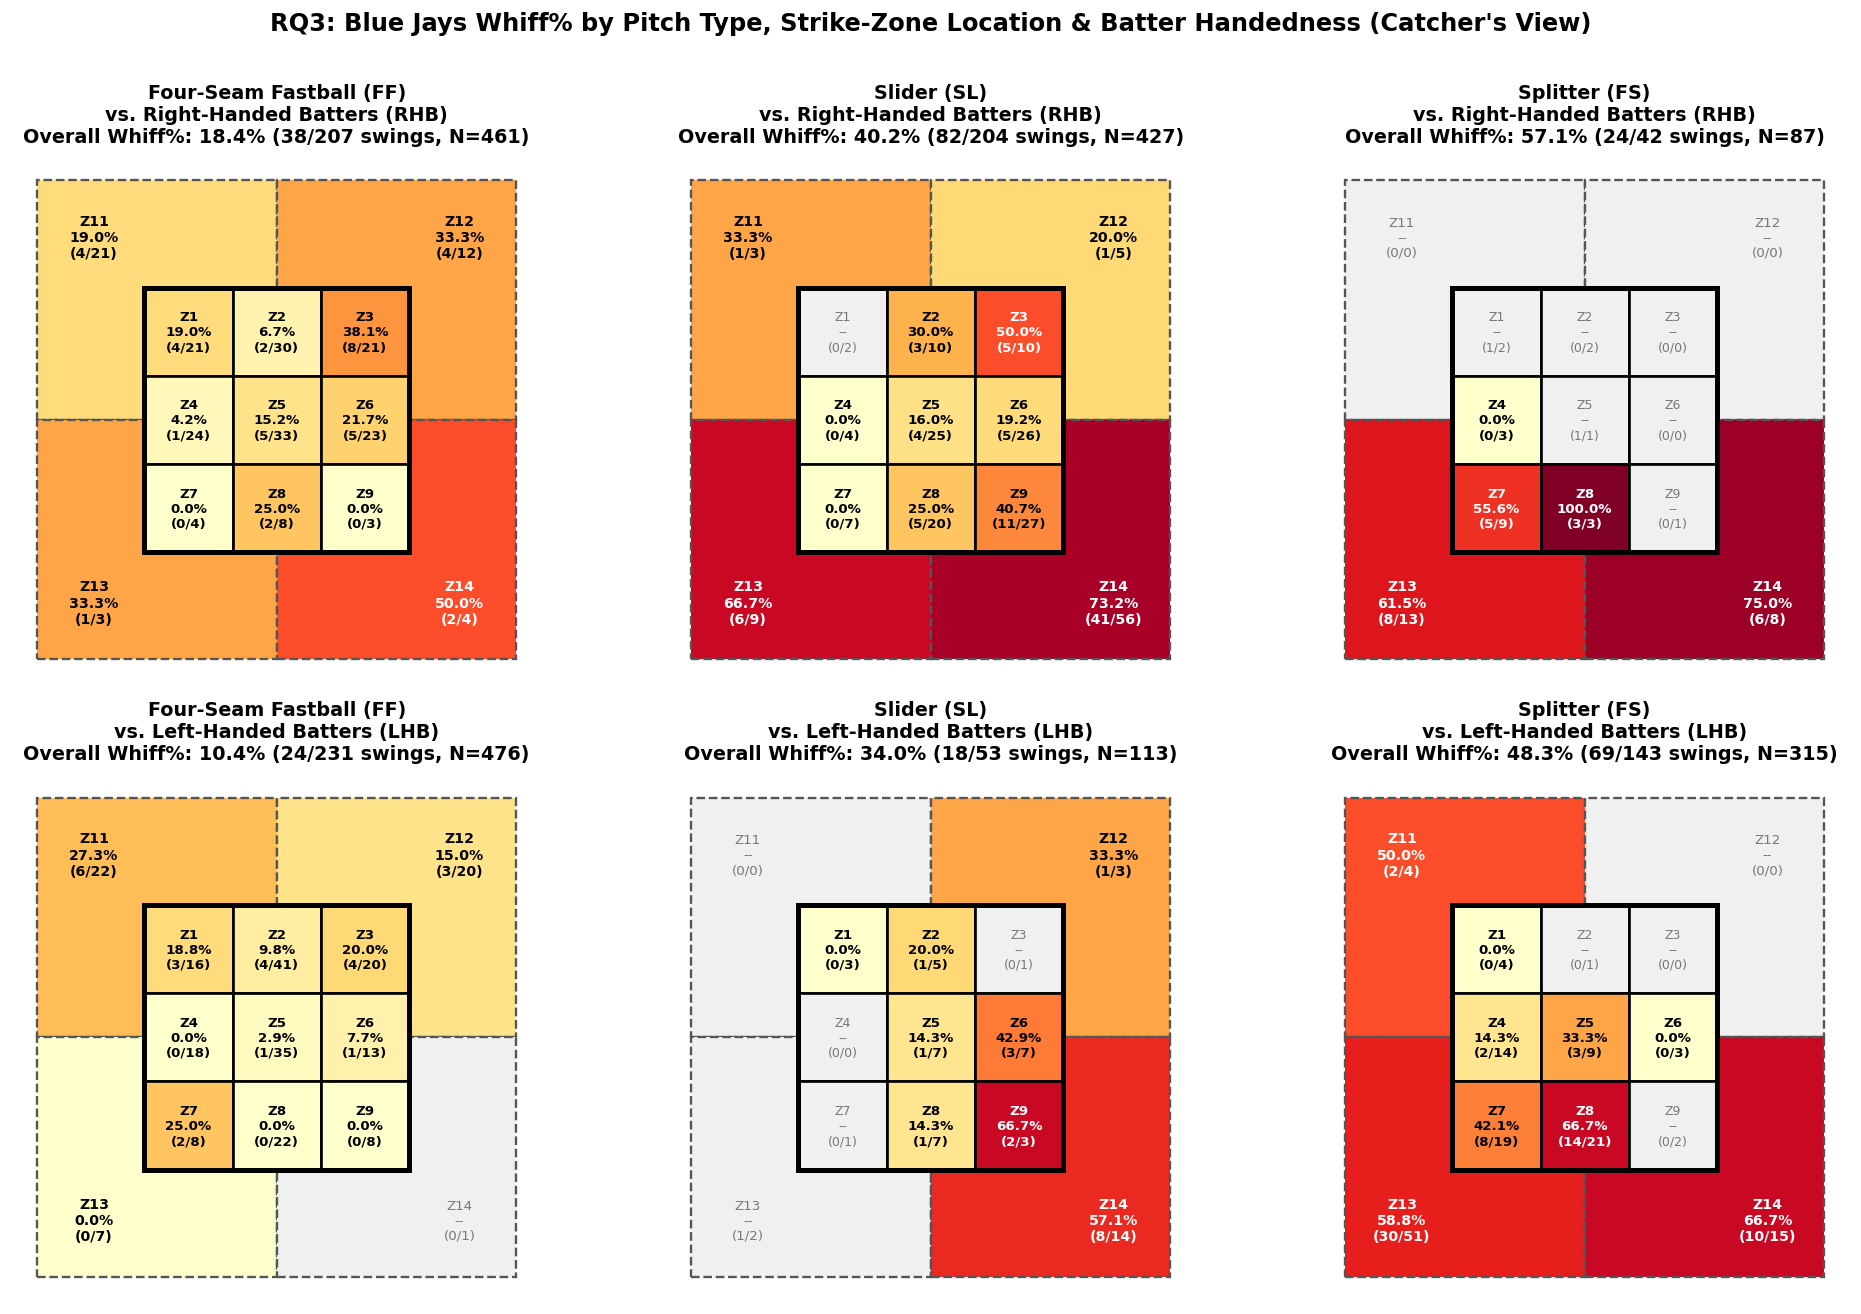

In [ ]:
def draw_whiff_zone(ax, df_sub, title, min_swings=3, cmap='YlOrRd'):
    ax.set_xlim(-2.1, 2.1)
    ax.set_ylim(-2.1, 2.1)
    ax.set_aspect('equal')
    ax.axis('off')
    ax.set_title(title, fontsize=11.5, fontweight='bold', pad=8)

    norm = plt.Normalize(vmin=0, vmax=80)
    colormap = plt.get_cmap(cmap)

    z_stats = {}
    for z in [1,2,3,4,5,6,7,8,9,11,12,13,14]:
        s = df_sub[df_sub['zone'] == z]
        pitches = len(s)
        swings = int(s['is_swing'].sum())
        whiffs = int(s['is_whiff'].sum())
        whiff_pct = (100.0 * whiffs / swings) if swings >= min_swings else np.nan
        z_stats[z] = (pitches, swings, whiffs, whiff_pct)

    outer_coords = {
        11: (-1.9, 0.0, 1.9, 1.9, -1.45, 1.45),
        12: (0.0, 0.0, 1.9, 1.9, 1.45, 1.45),
        13: (-1.9, -1.9, 1.9, 1.9, -1.45, -1.45),
        14: (0.0, -1.9, 1.9, 1.9, 1.45, -1.45),
    }
    for z, (x, y, w, h, tx, ty) in outer_coords.items():
        pitches, swings, whiffs, val = z_stats[z]
        color = colormap(norm(val)) if not np.isnan(val) else '#f0f0f0'
        rect = patches.Rectangle((x, y), w, h, facecolor=color, edgecolor='#555555', linewidth=1.4, linestyle='--')
        ax.add_patch(rect)
        if not np.isnan(val):
            tc = 'white' if norm(val) > 0.58 else 'black'
            ax.text(tx, ty, f'Z{z}\n{val:.1f}%\n({whiffs}/{swings})', ha='center', va='center', fontsize=8.5, fontweight='bold', color=tc)
        else:
            ax.text(tx, ty, f'Z{z}\n--\n({whiffs}/{swings})', ha='center', va='center', fontsize=8, color='#777777')

    inner_coords = {
        1: (-1.05, 0.35), 2: (-0.35, 0.35), 3: (0.35, 0.35),
        4: (-1.05, -0.35), 5: (-0.35, -0.35), 6: (0.35, -0.35),
        7: (-1.05, -1.05), 8: (-0.35, -1.05), 9: (0.35, -1.05)
    }
    for z, (x, y) in inner_coords.items():
        pitches, swings, whiffs, val = z_stats[z]
        color = colormap(norm(val)) if not np.isnan(val) else '#f0f0f0'
        rect = patches.Rectangle((x, y), 0.7, 0.7, facecolor=color, edgecolor='black', linewidth=1.6)
        ax.add_patch(rect)
        if not np.isnan(val):
            tc = 'white' if norm(val) > 0.58 else 'black'
            ax.text(x + 0.35, y + 0.35, f'Z{z}\n{val:.1f}%\n({whiffs}/{swings})', ha='center', va='center', fontsize=8, fontweight='bold', color=tc)
        else:
            ax.text(x + 0.35, y + 0.35, f'Z{z}\n--\n({whiffs}/{swings})', ha='center', va='center', fontsize=7.5, color='#777777')

    sz_border = patches.Rectangle((-1.05, -1.05), 2.1, 2.1, fill=False, edgecolor='black', linewidth=3.0)
    ax.add_patch(sz_border)

fig, axes = plt.subplots(2, 3, figsize=(16.5, 10.8), dpi=120)
pitches_to_plot = [('FF', 'Four-Seam Fastball (FF)'), ('SL', 'Slider (SL)'), ('FS', 'Splitter (FS)')]

for col_idx, (pt, pt_label) in enumerate(pitches_to_plot):
    for row_idx, (hand, hand_label) in enumerate([('R', 'vs. Right-Handed Batters (RHB)'), ('L', 'vs. Left-Handed Batters (LHB)')]):
        sub = rq3[(rq3['pitch_type'] == pt) & (rq3['stand'] == hand)]
        tot_p = len(sub)
        tot_s = int(sub['is_swing'].sum())
        tot_w = int(sub['is_whiff'].sum())
        overall_w = (100.0 * tot_w / tot_s) if tot_s > 0 else 0.0
        title = f'{pt_label}\n{hand_label}\nOverall Whiff%: {overall_w:.1f}% ({tot_w}/{tot_s} swings, N={tot_p})'
        draw_whiff_zone(axes[row_idx, col_idx], sub, title, min_swings=3, cmap='YlOrRd')

plt.suptitle("RQ3: Blue Jays Whiff% by Pitch Type, Strike-Zone Location & Batter Handedness (Catcher's View)", fontsize=14.5, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('RQ3_Fig1_StrikeZone_Heatmaps.png', bbox_inches='tight')
plt.show()

### Step 5: Tactical Region Matrix Heatmap & Top 12 Combinations Bar Chart

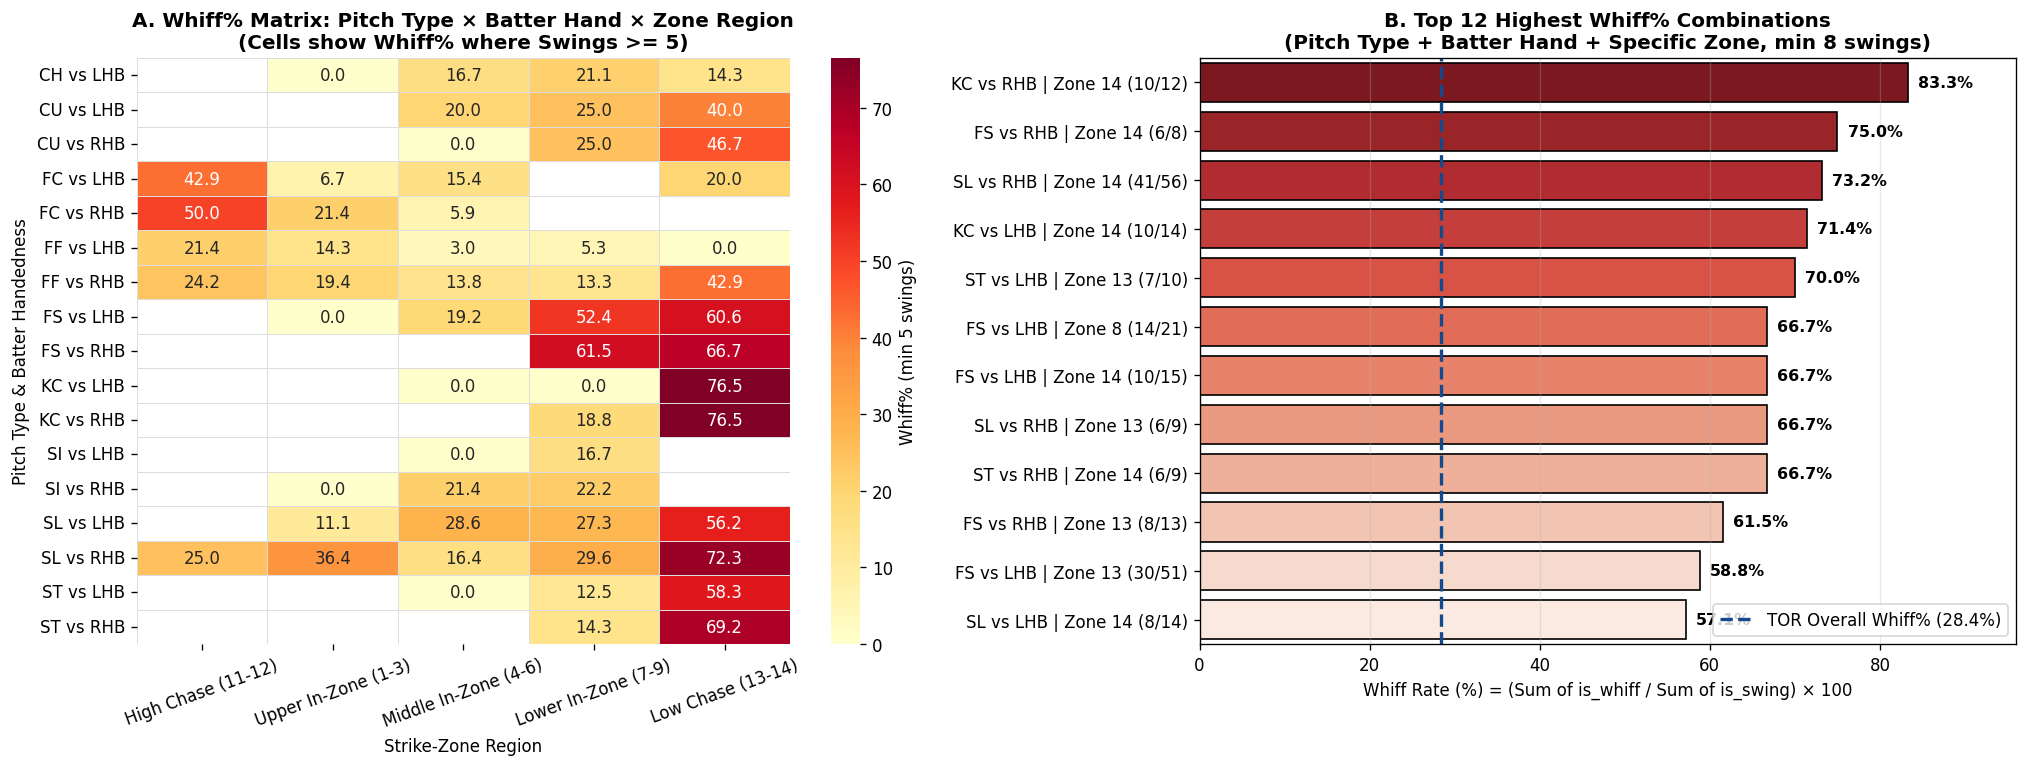

In [ ]:
def get_zone_group(z):
    if z in [1, 2, 3]: return 'Upper In-Zone (1-3)'
    elif z in [4, 5, 6]: return 'Middle In-Zone (4-6)'
    elif z in [7, 8, 9]: return 'Lower In-Zone (7-9)'
    elif z in [11, 12]: return 'High Chase (11-12)'
    elif z in [13, 14]: return 'Low Chase (13-14)'
    return 'Other'

rq3['zone_region'] = rq3['zone'].apply(get_zone_group)

reg_df = rq3.groupby(['pitch_type', 'stand', 'zone_region']).agg(
    Pitches=('is_swing', 'count'),
    Swings=('is_swing', 'sum'),
    Whiffs=('is_whiff', 'sum')
).reset_index()
reg_df['Whiff%'] = np.where(reg_df['Swings'] > 0, (100.0 * reg_df['Whiffs'] / reg_df['Swings']).round(2), np.nan)
reg_df['Pitch_Hand'] = reg_df['pitch_type'] + ' vs ' + reg_df['stand'] + 'HB'
reg_df['Whiff_Display'] = np.where(reg_df['Swings'] >= 5, reg_df['Whiff%'], np.nan)

zone_order = ['High Chase (11-12)', 'Upper In-Zone (1-3)', 'Middle In-Zone (4-6)', 'Lower In-Zone (7-9)', 'Low Chase (13-14)']
piv = reg_df.pivot(index='Pitch_Hand', columns='zone_region', values='Whiff_Display')[zone_order].dropna(how='all')

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), dpi=120)
sns.heatmap(piv, cmap='YlOrRd', annot=True, fmt='.1f', cbar_kws={'label': 'Whiff% (min 5 swings)'}, ax=axes[0], linewidths=0.5, linecolor='#dddddd')
axes[0].set_title('A. Whiff% Matrix: Pitch Type × Batter Hand × Zone Region\n(Cells show Whiff% where Swings >= 5)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Strike-Zone Region')
axes[0].set_ylabel('Pitch Type & Batter Handedness')
axes[0].tick_params(axis='x', rotation=20)

top12_plot = top12_combos.copy()
top12_plot['Combo_Label'] = top12_plot['pitch_type'] + ' vs ' + top12_plot['stand'] + 'HB | Zone ' + top12_plot['zone'].astype(str) + ' (' + top12_plot['Whiffs'].astype(str) + '/' + top12_plot['Swings'].astype(str) + ')'

sns.barplot(data=top12_plot, x='Whiff%', y='Combo_Label', hue='Combo_Label', palette='Reds_r', legend=False, ax=axes[1], edgecolor='black')
axes[1].axvline(28.38, color='#134A8E', linestyle='--', linewidth=2, label='TOR Overall Whiff% (28.4%)')
for i, (_, row) in enumerate(top12_plot.iterrows()):
    axes[1].text(row['Whiff%'] + 1.2, i, f"{row['Whiff%']:.1f}%", va='center', fontsize=9.5, fontweight='bold')
axes[1].set_xlim(0, 96)
axes[1].set_title('B. Top 12 Highest Whiff% Combinations\n(Pitch Type + Batter Hand + Specific Zone, min 8 swings)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Whiff Rate (%) = (Sum of is_whiff / Sum of is_swing) × 100')
axes[1].set_ylabel('')
axes[1].legend(loc='lower right')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('RQ3_Fig2_Matrix_and_Top12.png', bbox_inches='tight')
plt.show()

### Step 6: Formal Statistical Hypothesis Tests (Two-Proportion $z$-Tests)

In [ ]:
Z

In [ ]:
# Test 1: Secondary Pitches (SL, FS, KC, ST, CU, CH) in Low Chase (Zones 13-14) vs In-Zone (Zones 1-9)
sec = rq3[rq3['pitch_type'].isin(['SL', 'FS', 'KC', 'ST', 'CU', 'CH'])]
sec_low = sec[sec['zone'].isin([13, 14])]
sec_in = sec[sec['zone'].isin([1, 2, 3, 4, 5, 6, 7, 8, 9])]
z1, p1 = proportions_ztest([sec_low['is_whiff'].sum(), sec_in['is_whiff'].sum()], [sec_low['is_swing'].sum(), sec_in['is_swing'].sum()])
print(f"Test 1 (Secondary Pitches Low Chase vs In-Zone): {100*sec_low['is_whiff'].sum()/sec_low['is_swing'].sum():.2f}% vs {100*sec_in['is_whiff'].sum()/sec_in['is_swing'].sum():.2f}% | z = {z1:.3f}, p = {p1:.4e}")

# Test 2: Four-Seam Fastballs (FF) Elevated (Zones 1-3, 11-12) vs Middle/Low In-Zone (Zones 4-9)
ff = rq3[rq3['pitch_type'] == 'FF']
ff_high = ff[ff['zone'].isin([1, 2, 3, 11, 12])]
ff_low = ff[ff['zone'].isin([4, 5, 6, 7, 8, 9])]
z2, p2 = proportions_ztest([ff_high['is_whiff'].sum(), ff_low['is_whiff'].sum()], [ff_high['is_swing'].sum(), ff_low['is_swing'].sum()])
print(f"Test 2 (Four-Seamer Elevated vs Mid/Low): {100*ff_high['is_whiff'].sum()/ff_high['is_swing'].sum():.2f}% vs {100*ff_low['is_whiff'].sum()/ff_low['is_swing'].sum():.2f}% | z = {z2:.3f}, p = {p2:.5f}")

# Test 3: Overall Platoon Split (RHB vs LHB)
rhb = rq3[rq3['stand'] == 'R']
lhb = rq3[rq3['stand'] == 'L']
z3, p3 = proportions_ztest([rhb['is_whiff'].sum(), lhb['is_whiff'].sum()], [rhb['is_swing'].sum(), lhb['is_swing'].sum()])
print(f"Test 3 (Overall RHB vs LHB Whiff%): {100*rhb['is_whiff'].sum()/rhb['is_swing'].sum():.2f}% vs {100*lhb['is_whiff'].sum()/lhb['is_swing'].sum():.2f}% | z = {z3:.3f}, p = {p3:.5f}")

Test 1 (Secondary Pitches Low Chase vs In-Zone): 62.08% vs 24.70% | z = 9.763, p = 1.6229e-22
Test 2 (Four-Seamer Elevated vs Mid/Low): 18.75% vs 8.54% | z = 3.025, p = 0.00249
Test 3 (Overall RHB vs LHB Whiff%): 32.04% vs 24.77% | z = 2.908, p = 0.00364
